In [ ]:
# ==============================
# Peanut drought ML analysis
# Reproducible setup
# ==============================

import sys
import platform
import numpy as np
import pandas as pd
import sklearn

RANDOM_STATE = 42

print("Python version:", sys.version)
print("Platform:", platform.platform())
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("scikit-learn version:", sklearn.__version__)
print("Random state:", RANDOM_STATE)

Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.35
NumPy version: 2.0.2
Pandas version: 2.2.2
scikit-learn version: 1.6.1
Random state: 42


In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for name in uploaded.keys():
    print(name)

Saving sark_276_ComBatSeq_VST_for_ML_with_condition.csv to sark_276_ComBatSeq_VST_for_ML_with_condition.csv
Uploaded files:
sark_276_ComBatSeq_VST_for_ML_with_condition.csv


In [ ]:
# ==============================
# Cell 3: Load and verify dataset
# ==============================

FILE_NAME = "sark_276_ComBatSeq_VST_for_ML_with_condition.csv"

df = pd.read_csv(FILE_NAME)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nLast 10 column names:")
print(df.columns[-10:].tolist())

print("\nCondition counts:")
print(df["Condition"].value_counts())

print("\nBatch counts:")
print(df["Batch"].value_counts())

print("\nMissing values in entire dataset:", df.isna().sum().sum())

print("\nObject/string columns:")
print(df.select_dtypes(include="object").columns.tolist())

Dataset shape: (42, 279)

First 5 rows:


,Unnamed: 0,LOC112695140,LOC112695352,LOC112695500,LOC112695808,LOC112696620,LOC112696637,LOC112696808,LOC112697106,LOC112697186,...,LOC140179356,LOC140179465,LOC140179785,LOC140180412,LOC140181525,LOC140182814,LOC140182825,PNC1,Condition,Batch
0,SRR11362853,5.259246,9.279741,7.716995,7.430372,6.137681,7.103235,7.813660,4.884076,9.174469,...,5.144748,4.374376,4.374376,9.928350,6.679433,6.012862,5.643293,9.778340,Drought,Experiment2
1,SRR11362854,5.327053,9.086303,6.778168,5.171604,2.821810,7.519078,7.728446,6.666333,8.744756,...,5.171604,0.758212,2.821810,7.756022,2.821810,5.595117,0.758212,8.772023,Control,Experiment2
2,SRR11362855,5.142236,8.844155,8.424258,5.437432,2.802055,7.387473,7.724237,6.157290,9.218284,...,3.476278,0.758212,4.266115,8.598209,6.310698,7.081286,3.925978,2.802055,Control,Experiment2
3,SRR11362856,5.476071,8.560466,6.732481,5.476071,2.670401,6.822763,8.136570,4.576451,8.767824,...,4.082752,4.350913,3.316276,7.928708,6.636167,6.237079,5.233940,2.670401,Control,Experiment2
4,SRR11362857,6.042046,8.879697,7.222277,5.831616,3.173638,7.038330,6.749691,5.754037,8.642220,...,4.179395,5.492541,3.594811,8.576197,7.278724,4.760598,5.287409,10.063078,Drought,Experiment2



Last 10 column names:
['LOC140179356', 'LOC140179465', 'LOC140179785', 'LOC140180412', 'LOC140181525', 'LOC140182814', 'LOC140182825', 'PNC1', 'Condition', 'Batch']

Condition counts:
Condition
Drought    21
Control    21
Name: count, dtype: int64

Batch counts:
Batch
Experiment3    24
Experiment2    12
Experiment1     6
Name: count, dtype: int64

Missing values in entire dataset: 0

Object/string columns:
['Unnamed: 0', 'Condition', 'Batch']


In [ ]:
# ==============================
# Cell 4: Define predictors and outcome
# ==============================

from sklearn.preprocessing import LabelEncoder

# Sample IDs retained separately for later fold-level records
sample_ids = df["Unnamed: 0"].copy()

# 276 gene-expression predictors only
X = df.drop(columns=["Unnamed: 0", "Condition", "Batch"]).copy()

# Outcome
y = df["Condition"].copy()

# Encode outcome
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("X shape:", X.shape)
print("Number of samples:", X.shape[0])
print("Number of gene predictors:", X.shape[1])

print("\nClass encoding:")
for label, code in zip(label_encoder.classes_,
                       label_encoder.transform(label_encoder.classes_)):
    print(f"{label} = {code}")

print("\nClass counts:")
print(y.value_counts())

print("\nAll predictors numeric:", X.dtypes.apply(
    lambda x: np.issubdtype(x, np.number)).all())

print("Missing predictor values:", X.isna().sum().sum())

assert X.shape == (42, 276), "ERROR: Expected 42 samples × 276 genes"
assert X.isna().sum().sum() == 0, "ERROR: Missing values detected"

print("\n✓ Dataset is ready for machine learning.")

X shape: (42, 276)
Number of samples: 42
Number of gene predictors: 276

Class encoding:
Control = 0
Drought = 1

Class counts:
Condition
Drought    21
Control    21
Name: count, dtype: int64

All predictors numeric: True
Missing predictor values: 0

✓ Dataset is ready for machine learning.


In [ ]:
# ==========================================
# Cell 5: Nested repeated cross-validation
# ==========================================

from sklearn.model_selection import RepeatedStratifiedKFold

# Outer CV: unbiased model-performance estimation
outer_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=RANDOM_STATE
)

# Inner CV: hyperparameter tuning / feature-number selection
inner_cv = RepeatedStratifiedKFold(
    n_splits=4,
    n_repeats=3,
    random_state=RANDOM_STATE
)

print("Nested CV design")
print("----------------")
print("Outer CV: 5 folds × 10 repeats")
print("Outer test evaluations:", outer_cv.get_n_splits(X, y_encoded))

print("\nInner CV: 4 folds × 3 repeats")
print("Inner evaluations per outer training set:",
      inner_cv.get_n_splits())

print("\nRandom state:", RANDOM_STATE)

assert outer_cv.get_n_splits(X, y_encoded) == 50
assert inner_cv.get_n_splits() == 12

print("\n✓ Nested repeated CV configuration verified.")

Nested CV design
----------------
Outer CV: 5 folds × 10 repeats
Outer test evaluations: 50

Inner CV: 4 folds × 3 repeats
Inner evaluations per outer training set: 12

Random state: 42

✓ Nested repeated CV configuration verified.


In [ ]:
# ==========================================
# Cell 6: Define ANOVA pipelines and grids
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

K_VALUES = [5, 10, 15, 20, 30, 40, 50]

# Logistic Regression
pipe_lr = Pipeline([
    ("scale", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("clf", LogisticRegression(
        penalty="l2",
        solver="liblinear",
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

param_lr = {
    "select__k": K_VALUES,
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__class_weight": [None, "balanced"]
}

# Linear SVM
pipe_lsvm = Pipeline([
    ("scale", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("clf", SVC(kernel="linear", probability=True, random_state=RANDOM_STATE))
])

param_lsvm = {
    "select__k": K_VALUES,
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__class_weight": [None, "balanced"]
}

# RBF-SVM
pipe_rbf = Pipeline([
    ("scale", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("clf", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
])

param_rbf = {
    "select__k": K_VALUES,
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
    "clf__class_weight": [None, "balanced"]
}

# Random Forest
pipe_rf = Pipeline([
    ("select", SelectKBest(score_func=f_classif)),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE))
])

param_rf = {
    "select__k": K_VALUES,
    "clf__n_estimators": [200, 500],
    "clf__max_depth": [None, 3, 5, 10],
    "clf__min_samples_split": [2, 4, 6],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", "log2"],
    "clf__class_weight": [None, "balanced"]
}

# KNN
pipe_knn = Pipeline([
    ("scale", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("clf", KNeighborsClassifier())
])

param_knn = {
    "select__k": K_VALUES,
    "clf__n_neighbors": [1, 3, 5, 7, 9],
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["euclidean", "manhattan"]
}

print("✓ ANOVA pipelines and parameter grids defined.")

✓ ANOVA pipelines and parameter grids defined.


In [ ]:
# ==========================================
# Cell 7: Reusable nested-CV evaluation function
# ==========================================

import json
from collections import Counter

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score
)

def run_nested_cv(
    model_name,
    pipeline,
    param_grid,
    X,
    y_encoded,
    sample_ids,
    outer_cv,
    inner_cv
):
    fold_results = []
    prediction_records = []
    selected_gene_records = []
    hyperparameter_records = []

    print(f"\nStarting nested CV for {model_name}...")

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y_encoded), start=1
    ):
        X_train = X.iloc[train_idx]
        X_test  = X.iloc[test_idx]

        y_train = y_encoded[train_idx]
        y_test  = y_encoded[test_idx]

        # Inner-CV tuning
        grid = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            scoring="balanced_accuracy",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            verbose=0
        )

        grid.fit(X_train, y_train)

        best_model = grid.best_estimator_

        # Outer-test predictions
        y_pred = best_model.predict(X_test)

        if hasattr(best_model, "predict_proba"):
            y_score = best_model.predict_proba(X_test)[:, 1]
        elif hasattr(best_model, "decision_function"):
            y_score = best_model.decision_function(X_test)
        else:
            y_score = None

        # Metrics
        bal_acc = balanced_accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        mcc = matthews_corrcoef(y_test, y_pred)

        if y_score is not None:
            auc = roc_auc_score(y_test, y_score)
        else:
            auc = np.nan

        fold_results.append({
            "Model": model_name,
            "Outer_Fold": fold,
            "Balanced_Accuracy": bal_acc,
            "F1_Score": f1,
            "MCC": mcc,
            "ROC_AUC": auc,
            "Best_Inner_Balanced_Accuracy": grid.best_score_,
            "Selected_k": grid.best_params_.get("select__k", np.nan)
        })

        # Best hyperparameters
        hyperparameter_records.append({
            "Model": model_name,
            "Outer_Fold": fold,
            "Best_Params": json.dumps(grid.best_params_)
        })

        # Selected genes
        selector = best_model.named_steps["select"]
        selected_mask = selector.get_support()
        selected_genes = X.columns[selected_mask].tolist()

        for gene in selected_genes:
            selected_gene_records.append({
                "Model": model_name,
                "Outer_Fold": fold,
                "Gene": gene
            })

        # Outer-test predictions
        for j, idx in enumerate(test_idx):
            prediction_records.append({
                "Model": model_name,
                "Outer_Fold": fold,
                "Sample_ID": sample_ids.iloc[idx],
                "True_Label": int(y_encoded[idx]),
                "Predicted_Label": int(y_pred[j]),
                "Score": float(y_score[j]) if y_score is not None else np.nan
            })

        print(
            f"{model_name} | fold {fold:02d}/50 | "
            f"BA={bal_acc:.4f} | F1={f1:.4f} | MCC={mcc:.4f}"
        )

    # Convert to DataFrames
    fold_df = pd.DataFrame(fold_results)
    pred_df = pd.DataFrame(prediction_records)
    genes_df = pd.DataFrame(selected_gene_records)
    params_df = pd.DataFrame(hyperparameter_records)

    # Summary
    summary_df = pd.DataFrame({
        "Model": [model_name],
        "Balanced_Accuracy_Mean": [fold_df["Balanced_Accuracy"].mean()],
        "Balanced_Accuracy_SD": [fold_df["Balanced_Accuracy"].std(ddof=1)],
        "F1_Mean": [fold_df["F1_Score"].mean()],
        "F1_SD": [fold_df["F1_Score"].std(ddof=1)],
        "MCC_Mean": [fold_df["MCC"].mean()],
        "MCC_SD": [fold_df["MCC"].std(ddof=1)],
        "ROC_AUC_Mean": [fold_df["ROC_AUC"].mean()],
        "ROC_AUC_SD": [fold_df["ROC_AUC"].std(ddof=1)]
    })

    # Gene-selection frequency
    gene_freq_df = (
        genes_df.groupby(["Model", "Gene"])
        .size()
        .reset_index(name="Selection_Count")
    )

    gene_freq_df["Selection_Percentage"] = (
        gene_freq_df["Selection_Count"] / 50 * 100
    )

    gene_freq_df = gene_freq_df.sort_values(
        ["Selection_Count", "Gene"],
        ascending=[False, True]
    )

    # Save immediately
    safe_name = model_name.replace(" ", "_").replace("-", "_")

    fold_df.to_csv(f"{safe_name}_outer_fold_results.csv", index=False)
    pred_df.to_csv(f"{safe_name}_outer_predictions.csv", index=False)
    genes_df.to_csv(f"{safe_name}_selected_genes_by_fold.csv", index=False)
    params_df.to_csv(f"{safe_name}_best_hyperparameters.csv", index=False)
    summary_df.to_csv(f"{safe_name}_summary_mean_SD.csv", index=False)
    gene_freq_df.to_csv(f"{safe_name}_gene_selection_frequency.csv", index=False)

    print(f"\n✓ {model_name} complete.")
    print(summary_df)

    return {
        "fold_results": fold_df,
        "predictions": pred_df,
        "selected_genes": genes_df,
        "best_params": params_df,
        "summary": summary_df,
        "gene_frequency": gene_freq_df
    }

print("✓ Nested-CV function defined.")

✓ Nested-CV function defined.


In [ ]:
# ==========================================
# Cell 7: Reusable nested-CV evaluation function
# ==========================================

import json
from collections import Counter

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score
)

def run_nested_cv(
    model_name,
    pipeline,
    param_grid,
    X,
    y_encoded,
    sample_ids,
    outer_cv,
    inner_cv
):
    fold_results = []
    prediction_records = []
    selected_gene_records = []
    hyperparameter_records = []

    print(f"\nStarting nested CV for {model_name}...")

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y_encoded), start=1
    ):
        X_train = X.iloc[train_idx]
        X_test  = X.iloc[test_idx]

        y_train = y_encoded[train_idx]
        y_test  = y_encoded[test_idx]

        # Inner-CV tuning
        grid = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            scoring="balanced_accuracy",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            verbose=0
        )

        grid.fit(X_train, y_train)

        best_model = grid.best_estimator_

        # Outer-test predictions
        y_pred = best_model.predict(X_test)

        if hasattr(best_model, "predict_proba"):
            y_score = best_model.predict_proba(X_test)[:, 1]
        elif hasattr(best_model, "decision_function"):
            y_score = best_model.decision_function(X_test)
        else:
            y_score = None

        # Metrics
        bal_acc = balanced_accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        mcc = matthews_corrcoef(y_test, y_pred)

        if y_score is not None:
            auc = roc_auc_score(y_test, y_score)
        else:
            auc = np.nan

        fold_results.append({
            "Model": model_name,
            "Outer_Fold": fold,
            "Balanced_Accuracy": bal_acc,
            "F1_Score": f1,
            "MCC": mcc,
            "ROC_AUC": auc,
            "Best_Inner_Balanced_Accuracy": grid.best_score_,
            "Selected_k": grid.best_params_.get("select__k", np.nan)
        })

        # Best hyperparameters
        hyperparameter_records.append({
            "Model": model_name,
            "Outer_Fold": fold,
            "Best_Params": json.dumps(grid.best_params_)
        })

        # Selected genes
        selector = best_model.named_steps["select"]
        selected_mask = selector.get_support()
        selected_genes = X.columns[selected_mask].tolist()

        for gene in selected_genes:
            selected_gene_records.append({
                "Model": model_name,
                "Outer_Fold": fold,
                "Gene": gene
            })

        # Outer-test predictions
        for j, idx in enumerate(test_idx):
            prediction_records.append({
                "Model": model_name,
                "Outer_Fold": fold,
                "Sample_ID": sample_ids.iloc[idx],
                "True_Label": int(y_encoded[idx]),
                "Predicted_Label": int(y_pred[j]),
                "Score": float(y_score[j]) if y_score is not None else np.nan
            })

        print(
            f"{model_name} | fold {fold:02d}/50 | "
            f"BA={bal_acc:.4f} | F1={f1:.4f} | MCC={mcc:.4f}"
        )

    # Convert to DataFrames
    fold_df = pd.DataFrame(fold_results)
    pred_df = pd.DataFrame(prediction_records)
    genes_df = pd.DataFrame(selected_gene_records)
    params_df = pd.DataFrame(hyperparameter_records)

    # Summary
    summary_df = pd.DataFrame({
        "Model": [model_name],
        "Balanced_Accuracy_Mean": [fold_df["Balanced_Accuracy"].mean()],
        "Balanced_Accuracy_SD": [fold_df["Balanced_Accuracy"].std(ddof=1)],
        "F1_Mean": [fold_df["F1_Score"].mean()],
        "F1_SD": [fold_df["F1_Score"].std(ddof=1)],
        "MCC_Mean": [fold_df["MCC"].mean()],
        "MCC_SD": [fold_df["MCC"].std(ddof=1)],
        "ROC_AUC_Mean": [fold_df["ROC_AUC"].mean()],
        "ROC_AUC_SD": [fold_df["ROC_AUC"].std(ddof=1)]
    })

    # Gene-selection frequency
    gene_freq_df = (
        genes_df.groupby(["Model", "Gene"])
        .size()
        .reset_index(name="Selection_Count")
    )

    gene_freq_df["Selection_Percentage"] = (
        gene_freq_df["Selection_Count"] / 50 * 100
    )

    gene_freq_df = gene_freq_df.sort_values(
        ["Selection_Count", "Gene"],
        ascending=[False, True]
    )

    # Save immediately
    safe_name = model_name.replace(" ", "_").replace("-", "_")

    fold_df.to_csv(f"{safe_name}_outer_fold_results.csv", index=False)
    pred_df.to_csv(f"{safe_name}_outer_predictions.csv", index=False)
    genes_df.to_csv(f"{safe_name}_selected_genes_by_fold.csv", index=False)
    params_df.to_csv(f"{safe_name}_best_hyperparameters.csv", index=False)
    summary_df.to_csv(f"{safe_name}_summary_mean_SD.csv", index=False)
    gene_freq_df.to_csv(f"{safe_name}_gene_selection_frequency.csv", index=False)

    print(f"\n✓ {model_name} complete.")
    print(summary_df)

    return {
        "fold_results": fold_df,
        "predictions": pred_df,
        "selected_genes": genes_df,
        "best_params": params_df,
        "summary": summary_df,
        "gene_frequency": gene_freq_df
    }

print("✓ Nested-CV function defined.")

✓ Nested-CV function defined.


In [ ]:
# ==========================================
# Cell 8: ANOVA + Logistic Regression
# ==========================================

results_lr = run_nested_cv(
    model_name="Logistic Regression",
    pipeline=pipe_lr,
    param_grid=param_lr,
    X=X,
    y_encoded=y_encoded,
    sample_ids=sample_ids,
    outer_cv=outer_cv,
    inner_cv=inner_cv
)


Starting nested CV for Logistic Regression...
Logistic Regression | fold 01/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Logistic Regression | fold 02/50 | BA=0.8000 | F1=0.8000 | MCC=0.6325
Logistic Regression | fold 03/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Logistic Regression | fold 04/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Logistic Regression | fold 05/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
Logistic Regression | fold 06/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Logistic Regression | fold 07/50 | BA=0.7750 | F1=0.7500 | MCC=0.5500
Logistic Regression | fold 08/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Logistic Regression | fold 09/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Logistic Regression | fold 10/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Logistic Regression | fold 11/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Logistic Regression | fold 12/50 | BA=0.8750 | F1=0.8571 | MCC=0.7906
Logistic Regression | fold 13/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Logistic Regression | fold 14/50 | BA=1.000

In [ ]:
# ==========================================
# Cell 9: ANOVA + Linear SVM
# ==========================================

results_lsvm = run_nested_cv(
    model_name="Linear SVM",
    pipeline=pipe_lsvm,
    param_grid=param_lsvm,
    X=X,
    y_encoded=y_encoded,
    sample_ids=sample_ids,
    outer_cv=outer_cv,
    inner_cv=inner_cv
)


Starting nested CV for Linear SVM...
Linear SVM | fold 01/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Linear SVM | fold 02/50 | BA=0.8000 | F1=0.8000 | MCC=0.6325
Linear SVM | fold 03/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Linear SVM | fold 04/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Linear SVM | fold 05/50 | BA=0.7500 | F1=0.7500 | MCC=0.5000
Linear SVM | fold 06/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Linear SVM | fold 07/50 | BA=0.7750 | F1=0.7500 | MCC=0.5500
Linear SVM | fold 08/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Linear SVM | fold 09/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Linear SVM | fold 10/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Linear SVM | fold 11/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Linear SVM | fold 12/50 | BA=0.8750 | F1=0.8571 | MCC=0.7906
Linear SVM | fold 13/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Linear SVM | fold 14/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Linear SVM | fold 15/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
Linear SVM | fold 16/50 | BA=1.0000 | F1=1.0000

In [ ]:
# ==========================================
# Cell 10: ANOVA + Random Forest
# ==========================================

results_rf = run_nested_cv(
    model_name="Random Forest",
    pipeline=pipe_rf,
    param_grid=param_rf,
    X=X,
    y_encoded=y_encoded,
    sample_ids=sample_ids,
    outer_cv=outer_cv,
    inner_cv=inner_cv
)


Starting nested CV for Random Forest...


KeyboardInterrupt: 

In [ ]:
# ==========================================
# Cell 11: ANOVA + KNN
# ==========================================

results_knn = run_nested_cv(
    model_name="KNN",
    pipeline=pipe_knn,
    param_grid=param_knn,
    X=X,
    y_encoded=y_encoded,
    sample_ids=sample_ids,
    outer_cv=outer_cv,
    inner_cv=inner_cv
)


Starting nested CV for KNN...
KNN | fold 01/50 | BA=0.9000 | F1=0.8889 | MCC=0.8000
KNN | fold 02/50 | BA=0.8000 | F1=0.8000 | MCC=0.6325
KNN | fold 03/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
KNN | fold 04/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
KNN | fold 05/50 | BA=0.7500 | F1=0.6667 | MCC=0.5774
KNN | fold 06/50 | BA=0.9000 | F1=0.8889 | MCC=0.8000
KNN | fold 07/50 | BA=0.7750 | F1=0.7500 | MCC=0.5500
KNN | fold 08/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
KNN | fold 09/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
KNN | fold 10/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
KNN | fold 11/50 | BA=0.7750 | F1=0.8000 | MCC=0.5500
KNN | fold 12/50 | BA=0.7750 | F1=0.7500 | MCC=0.5500
KNN | fold 13/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
KNN | fold 14/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
KNN | fold 15/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
KNN | fold 16/50 | BA=0.7750 | F1=0.8000 | MCC=0.5500
KNN | fold 17/50 | BA=0.9000 | F1=0.8889 | MCC=0.8000
KNN | fold 18/50 | BA=0.7500 | F1=0.6667 | MCC=0.57

In [ ]:
# ==========================================
# Cell 12: ANOVA + RBF-SVM
# ==========================================

results_rbf = run_nested_cv(
    model_name="RBF-SVM",
    pipeline=pipe_rbf,
    param_grid=param_rbf,
    X=X,
    y_encoded=y_encoded,
    sample_ids=sample_ids,
    outer_cv=outer_cv,
    inner_cv=inner_cv
)


Starting nested CV for RBF-SVM...
RBF-SVM | fold 01/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 02/50 | BA=0.8000 | F1=0.8000 | MCC=0.6325
RBF-SVM | fold 03/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 04/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 05/50 | BA=0.7500 | F1=0.7500 | MCC=0.5000
RBF-SVM | fold 06/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 07/50 | BA=0.7750 | F1=0.7500 | MCC=0.5500
RBF-SVM | fold 08/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 09/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 10/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 11/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 12/50 | BA=0.8750 | F1=0.8571 | MCC=0.7906
RBF-SVM | fold 13/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 14/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 15/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 16/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
RBF-SVM | fold 17/50 | BA=0.7750 | F1

In [ ]:
# ==========================================
# Cell 13: PCA-based gene-ranking selector
# ==========================================

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

class PCAGeneSelector(BaseEstimator, TransformerMixin):
    """
    Rank genes using PCA loadings calculated from training data only.

    Steps:
    1. Standardize training data.
    2. Fit PCA retaining enough components to explain >=80% variance.
    3. Calculate gene importance:
       sum(|loading| × explained variance ratio)
       across retained PCs.
    4. Retain the top k genes.
    """

    def __init__(self, k=20, variance_threshold=0.80):
        self.k = k
        self.variance_threshold = variance_threshold

    def fit(self, X, y=None):

        # Preserve feature names when X is a DataFrame
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.array(X.columns)
        else:
            self.feature_names_in_ = np.array(
                [f"feature_{i}" for i in range(X.shape[1])]
            )

        # Standardize TRAINING data only
        self.scaler_ = StandardScaler()
        X_scaled = self.scaler_.fit_transform(X)

        # Retain minimum PCs explaining ~80% cumulative variance
        self.pca_ = PCA(
            n_components=self.variance_threshold,
            svd_solver="full"
        )

        self.pca_.fit(X_scaled)

        # PCA loadings: genes × retained PCs
        loadings = self.pca_.components_.T

        # Weight absolute loadings by variance explained by each PC
        self.gene_scores_ = np.sum(
            np.abs(loadings) * self.pca_.explained_variance_ratio_,
            axis=1
        )

        # Rank genes from highest to lowest PCA importance
        ranked_indices = np.argsort(self.gene_scores_)[::-1]

        # Retain top k
        self.selected_indices_ = ranked_indices[:self.k]

        self.support_mask_ = np.zeros(
            X.shape[1],
            dtype=bool
        )
        self.support_mask_[self.selected_indices_] = True

        self.n_components_retained_ = self.pca_.n_components_
        self.cumulative_variance_ = (
            self.pca_.explained_variance_ratio_.sum()
        )

        return self

    def transform(self, X):
        # Return selected ORIGINAL gene-expression columns
        if hasattr(X, "iloc"):
            return X.iloc[:, self.selected_indices_]
        return X[:, self.selected_indices_]

    def get_support(self):
        return self.support_mask_


print("✓ PCA gene-ranking selector defined.")

✓ PCA gene-ranking selector defined.


In [ ]:
# ==========================================
# Cell 14: Define PCA-based pipelines
# ==========================================

# Logistic Regression
pipe_pca_lr = Pipeline([
    ("select", PCAGeneSelector(variance_threshold=0.80)),
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(
        penalty="l2",
        solver="liblinear",
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

param_pca_lr = {
    "select__k": K_VALUES,
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__class_weight": [None, "balanced"]
}

# Linear SVM
pipe_pca_lsvm = Pipeline([
    ("select", PCAGeneSelector(variance_threshold=0.80)),
    ("scale", StandardScaler()),
    ("clf", SVC(
        kernel="linear",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

param_pca_lsvm = {
    "select__k": K_VALUES,
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__class_weight": [None, "balanced"]
}

# RBF-SVM
pipe_pca_rbf = Pipeline([
    ("select", PCAGeneSelector(variance_threshold=0.80)),
    ("scale", StandardScaler()),
    ("clf", SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

param_pca_rbf = {
    "select__k": K_VALUES,
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
    "clf__class_weight": [None, "balanced"]
}

# KNN
pipe_pca_knn = Pipeline([
    ("select", PCAGeneSelector(variance_threshold=0.80)),
    ("scale", StandardScaler()),
    ("clf", KNeighborsClassifier())
])

param_pca_knn = {
    "select__k": K_VALUES,
    "clf__n_neighbors": [1, 3, 5, 7, 9],
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["euclidean", "manhattan"]
}

print("✓ PCA-based pipelines and parameter grids defined.")

✓ PCA-based pipelines and parameter grids defined.


In [ ]:
# ==========================================
# Cell 15: PCA + Logistic Regression
# ==========================================

results_pca_lr = run_nested_cv(
    model_name="PCA Logistic Regression",
    pipeline=pipe_pca_lr,
    param_grid=param_pca_lr,
    X=X,
    y_encoded=y_encoded,
    sample_ids=sample_ids,
    outer_cv=outer_cv,
    inner_cv=inner_cv
)


Starting nested CV for PCA Logistic Regression...
PCA Logistic Regression | fold 01/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA Logistic Regression | fold 02/50 | BA=0.9000 | F1=0.8889 | MCC=0.8000
PCA Logistic Regression | fold 03/50 | BA=0.8750 | F1=0.8889 | MCC=0.7746
PCA Logistic Regression | fold 04/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA Logistic Regression | fold 05/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
PCA Logistic Regression | fold 06/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA Logistic Regression | fold 07/50 | BA=0.6750 | F1=0.6667 | MCC=0.3500
PCA Logistic Regression | fold 08/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
PCA Logistic Regression | fold 09/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA Logistic Regression | fold 10/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA Logistic Regression | fold 11/50 | BA=0.9000 | F1=0.8889 | MCC=0.8000
PCA Logistic Regression | fold 12/50 | BA=0.9000 | F1=0.8889 | MCC=0.8000
PCA Logistic Regression | fold 13/50 | BA=1.0000 | F1=1.0000 

In [ ]:
# ==========================================
# Cell 16: PCA + Linear SVM
# ==========================================

results_pca_lsvm = run_nested_cv(
    model_name="PCA Linear SVM",
    pipeline=pipe_pca_lsvm,
    param_grid=param_pca_lsvm,
    X=X,
    y_encoded=y_encoded,
    sample_ids=sample_ids,
    outer_cv=outer_cv,
    inner_cv=inner_cv
)


Starting nested CV for PCA Linear SVM...
PCA Linear SVM | fold 01/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA Linear SVM | fold 02/50 | BA=0.8000 | F1=0.8000 | MCC=0.6325
PCA Linear SVM | fold 03/50 | BA=0.8750 | F1=0.8889 | MCC=0.7746
PCA Linear SVM | fold 04/50 | BA=0.8750 | F1=0.8889 | MCC=0.7746
PCA Linear SVM | fold 05/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA Linear SVM | fold 06/50 | BA=0.8750 | F1=0.9091 | MCC=0.7906
PCA Linear SVM | fold 07/50 | BA=0.6750 | F1=0.6667 | MCC=0.3500
PCA Linear SVM | fold 08/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
PCA Linear SVM | fold 09/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA Linear SVM | fold 10/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA Linear SVM | fold 11/50 | BA=0.9000 | F1=0.8889 | MCC=0.8000
PCA Linear SVM | fold 12/50 | BA=0.9000 | F1=0.8889 | MCC=0.8000
PCA Linear SVM | fold 13/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
PCA Linear SVM | fold 14/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
PCA Linear SVM | fold 15/50 | BA=1.0000 | F1=1.0

In [ ]:
# ==========================================
# PCA + RBF-SVM
# ==========================================

results_pca_rbf = run_nested_cv(
    model_name="PCA RBF-SVM",
    pipeline=pipe_pca_rbf,
    param_grid=param_pca_rbf,
    X=X,
    y_encoded=y_encoded,
    sample_ids=sample_ids,
    outer_cv=outer_cv,
    inner_cv=inner_cv
)


Starting nested CV for PCA RBF-SVM...
PCA RBF-SVM | fold 01/50 | BA=0.8750 | F1=0.9091 | MCC=0.7906
PCA RBF-SVM | fold 02/50 | BA=0.8000 | F1=0.8000 | MCC=0.6325
PCA RBF-SVM | fold 03/50 | BA=0.8750 | F1=0.8889 | MCC=0.7746
PCA RBF-SVM | fold 04/50 | BA=0.8750 | F1=0.8889 | MCC=0.7746
PCA RBF-SVM | fold 05/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
PCA RBF-SVM | fold 06/50 | BA=0.8750 | F1=0.9091 | MCC=0.7906
PCA RBF-SVM | fold 07/50 | BA=0.8000 | F1=0.8000 | MCC=0.6325
PCA RBF-SVM | fold 08/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
PCA RBF-SVM | fold 09/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
PCA RBF-SVM | fold 10/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA RBF-SVM | fold 11/50 | BA=0.7750 | F1=0.8000 | MCC=0.5500
PCA RBF-SVM | fold 12/50 | BA=0.8750 | F1=0.8571 | MCC=0.7906
PCA RBF-SVM | fold 13/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA RBF-SVM | fold 14/50 | BA=0.7500 | F1=0.6667 | MCC=0.5774
PCA RBF-SVM | fold 15/50 | BA=0.8750 | F1=0.8889 | MCC=0.7746
PCA RBF-SVM | fold 16/50 | BA=0

In [ ]:
# ==========================================
# PCA + KNN
# ==========================================

results_pca_knn = run_nested_cv(
    model_name="PCA KNN",
    pipeline=pipe_pca_knn,
    param_grid=param_pca_knn,
    X=X,
    y_encoded=y_encoded,
    sample_ids=sample_ids,
    outer_cv=outer_cv,
    inner_cv=inner_cv
)


Starting nested CV for PCA KNN...
PCA KNN | fold 01/50 | BA=0.9000 | F1=0.8889 | MCC=0.8000
PCA KNN | fold 02/50 | BA=0.8000 | F1=0.8000 | MCC=0.6325
PCA KNN | fold 03/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA KNN | fold 04/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA KNN | fold 05/50 | BA=0.7500 | F1=0.7500 | MCC=0.5000
PCA KNN | fold 06/50 | BA=0.7750 | F1=0.8000 | MCC=0.5500
PCA KNN | fold 07/50 | BA=0.8750 | F1=0.8571 | MCC=0.7906
PCA KNN | fold 08/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA KNN | fold 09/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
PCA KNN | fold 10/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA KNN | fold 11/50 | BA=0.8000 | F1=0.7500 | MCC=0.6325
PCA KNN | fold 12/50 | BA=0.8750 | F1=0.8571 | MCC=0.7906
PCA KNN | fold 13/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA KNN | fold 14/50 | BA=0.8750 | F1=0.8571 | MCC=0.7746
PCA KNN | fold 15/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA KNN | fold 16/50 | BA=1.0000 | F1=1.0000 | MCC=1.0000
PCA KNN | fold 17/50 | BA=0.9000 | F1

In [ ]:
# ==========================================================
# Cell 18: Compare recurrent genes across 3 selected pipelines
# ==========================================================

# Retrieve gene-selection frequency tables
freq_anova_lr = results_lr["gene_frequency"].copy()
freq_anova_lsvm = results_lsvm["gene_frequency"].copy()
freq_pca_lsvm = results_pca_lsvm["gene_frequency"].copy()

# Rename frequency columns for comparison
freq_anova_lr = freq_anova_lr[
    ["Gene", "Selection_Count", "Selection_Percentage"]
].rename(columns={
    "Selection_Count": "ANOVA_LR_Count",
    "Selection_Percentage": "ANOVA_LR_Percent"
})

freq_anova_lsvm = freq_anova_lsvm[
    ["Gene", "Selection_Count", "Selection_Percentage"]
].rename(columns={
    "Selection_Count": "ANOVA_LinearSVM_Count",
    "Selection_Percentage": "ANOVA_LinearSVM_Percent"
})

freq_pca_lsvm = freq_pca_lsvm[
    ["Gene", "Selection_Count", "Selection_Percentage"]
].rename(columns={
    "Selection_Count": "PCA_LinearSVM_Count",
    "Selection_Percentage": "PCA_LinearSVM_Percent"
})

# Merge all genes
comparison = (
    freq_anova_lr
    .merge(freq_anova_lsvm, on="Gene", how="outer")
    .merge(freq_pca_lsvm, on="Gene", how="outer")
    .fillna(0)
)

# Number of pipelines in which each gene was selected at least once
comparison["Pipelines_Selected"] = (
    (comparison["ANOVA_LR_Count"] > 0).astype(int) +
    (comparison["ANOVA_LinearSVM_Count"] > 0).astype(int) +
    (comparison["PCA_LinearSVM_Count"] > 0).astype(int)
)

# Mean recurrence across the three pipelines
comparison["Mean_Selection_Percent"] = comparison[
    [
        "ANOVA_LR_Percent",
        "ANOVA_LinearSVM_Percent",
        "PCA_LinearSVM_Percent"
    ]
].mean(axis=1)

# Sort strongest consensus genes first
comparison = comparison.sort_values(
    ["Pipelines_Selected", "Mean_Selection_Percent"],
    ascending=[False, False]
).reset_index(drop=True)

print("Top 30 genes across the three pipelines:")
display(comparison.head(30))

# Save
comparison.to_csv(
    "Consensus_gene_selection_comparison.csv",
    index=False
)

print("\n✓ Consensus comparison saved.")

Top 30 genes across the three pipelines:


,Gene,ANOVA_LR_Count,ANOVA_LR_Percent,ANOVA_LinearSVM_Count,ANOVA_LinearSVM_Percent,PCA_LinearSVM_Count,PCA_LinearSVM_Percent,Pipelines_Selected,Mean_Selection_Percent
0,LOC112784224,47.0,94.0,45.0,90.0,48.0,96.0,3,93.333333
1,LOC112733679,48.0,96.0,48.0,96.0,38.0,76.0,3,89.333333
2,LOC112775500,49.0,98.0,49.0,98.0,36.0,72.0,3,89.333333
3,LOC112795505,46.0,92.0,47.0,94.0,38.0,76.0,3,87.333333
4,LOC112720488,40.0,80.0,37.0,74.0,46.0,92.0,3,82.000000
5,LOC112741057,44.0,88.0,42.0,84.0,34.0,68.0,3,80.000000
6,LOC112764030,50.0,100.0,50.0,100.0,18.0,36.0,3,78.666667
7,LOC112803160,48.0,96.0,49.0,98.0,21.0,42.0,3,78.666667
8,LOC112734805,48.0,96.0,48.0,96.0,14.0,28.0,3,73.333333
9,LOC112767328,50.0,100.0,50.0,100.0,9.0,18.0,3,72.666667



✓ Consensus comparison saved.


In [ ]:
# ==========================================
# Cell 19: Define robust consensus genes
# ==========================================

# Count how many pipelines show >=50% recurrence
comparison["Pipelines_50pct_or_more"] = (
    (comparison["ANOVA_LR_Percent"] >= 50).astype(int) +
    (comparison["ANOVA_LinearSVM_Percent"] >= 50).astype(int) +
    (comparison["PCA_LinearSVM_Percent"] >= 50).astype(int)
)

# Consensus rule:
# gene must reach >=50% recurrence in at least 2 of 3 pipelines
robust_consensus = comparison[
    comparison["Pipelines_50pct_or_more"] >= 2
].copy()

robust_consensus = robust_consensus.sort_values(
    ["Pipelines_50pct_or_more", "Mean_Selection_Percent"],
    ascending=[False, False]
).reset_index(drop=True)

print("Number of robust consensus genes:",
      len(robust_consensus))

display(robust_consensus)

robust_consensus.to_csv(
    "Robust_consensus_genes_50pct_2of3.csv",
    index=False
)

print("\n✓ Robust consensus genes saved.")

Number of robust consensus genes: 34


,Gene,ANOVA_LR_Count,ANOVA_LR_Percent,ANOVA_LinearSVM_Count,ANOVA_LinearSVM_Percent,PCA_LinearSVM_Count,PCA_LinearSVM_Percent,Pipelines_Selected,Mean_Selection_Percent,Pipelines_50pct_or_more
0,LOC112784224,47.0,94.0,45.0,90.0,48.0,96.0,3,93.333333,3
1,LOC112733679,48.0,96.0,48.0,96.0,38.0,76.0,3,89.333333,3
2,LOC112775500,49.0,98.0,49.0,98.0,36.0,72.0,3,89.333333,3
3,LOC112795505,46.0,92.0,47.0,94.0,38.0,76.0,3,87.333333,3
4,LOC112720488,40.0,80.0,37.0,74.0,46.0,92.0,3,82.000000,3
5,LOC112741057,44.0,88.0,42.0,84.0,34.0,68.0,3,80.000000,3
6,LOC112755969,32.0,64.0,33.0,66.0,36.0,72.0,3,67.333333,3
7,LOC112790749,29.0,58.0,27.0,54.0,34.0,68.0,3,60.000000,3
8,LOC112764030,50.0,100.0,50.0,100.0,18.0,36.0,3,78.666667,2
9,LOC112803160,48.0,96.0,49.0,98.0,21.0,42.0,3,78.666667,2



✓ Robust consensus genes saved.


In [ ]:
# ======================================================
# Cell 20: Sensitivity of consensus gene threshold
# ======================================================

thresholds = [50, 60, 70, 80, 90]

rows = []

for threshold in thresholds:
    counts = (
        (comparison["ANOVA_LR_Percent"] >= threshold).astype(int) +
        (comparison["ANOVA_LinearSVM_Percent"] >= threshold).astype(int) +
        (comparison["PCA_LinearSVM_Percent"] >= threshold).astype(int)
    )

    rows.append({
        "Recurrence_threshold": threshold,
        "At_least_1_of_3": (counts >= 1).sum(),
        "At_least_2_of_3": (counts >= 2).sum(),
        "All_3": (counts == 3).sum()
    })

threshold_sensitivity = pd.DataFrame(rows)

display(threshold_sensitivity)

threshold_sensitivity.to_csv(
    "Consensus_threshold_sensitivity.csv",
    index=False
)

,Recurrence_threshold,At_least_1_of_3,At_least_2_of_3,All_3
0,50,57,34,8
1,60,43,28,7
2,70,36,24,5
3,80,24,19,1
4,90,16,14,1


In [ ]:
# ==========================================================
# Cell 21: Strict cross-pipeline consensus genes
# ==========================================================

strict_consensus = comparison[
    (comparison["ANOVA_LR_Percent"] >= 50) &
    (comparison["ANOVA_LinearSVM_Percent"] >= 50) &
    (comparison["PCA_LinearSVM_Percent"] >= 50)
].copy()

strict_consensus = strict_consensus.sort_values(
    "Mean_Selection_Percent",
    ascending=False
).reset_index(drop=True)

print("Strict consensus genes:", len(strict_consensus))
print(
    "Criterion: >=50% selection frequency in ALL THREE pipelines\n"
)

display(
    strict_consensus[
        [
            "Gene",
            "ANOVA_LR_Percent",
            "ANOVA_LinearSVM_Percent",
            "PCA_LinearSVM_Percent",
            "Mean_Selection_Percent"
        ]
    ]
)

strict_consensus.to_csv(
    "Strict_consensus_genes_all3_50pct.csv",
    index=False
)

print("\n✓ Strict consensus gene table saved.")

Strict consensus genes: 8
Criterion: >=50% selection frequency in ALL THREE pipelines



,Gene,ANOVA_LR_Percent,ANOVA_LinearSVM_Percent,PCA_LinearSVM_Percent,Mean_Selection_Percent
0,LOC112784224,94.0,90.0,96.0,93.333333
1,LOC112733679,96.0,96.0,76.0,89.333333
2,LOC112775500,98.0,98.0,72.0,89.333333
3,LOC112795505,92.0,94.0,76.0,87.333333
4,LOC112720488,80.0,74.0,92.0,82.000000
5,LOC112741057,88.0,84.0,68.0,80.000000
6,LOC112755969,64.0,66.0,72.0,67.333333
7,LOC112790749,58.0,54.0,68.0,60.000000



✓ Strict consensus gene table saved.


In [ ]:
# ==========================================================
# Cell 22: Inspect ANOVA-LR hyperparameter stability
# ==========================================================

params_lr = results_lr["best_params"].copy()

print("Number of outer-fold parameter records:", len(params_lr))
print("\nColumns:")
print(params_lr.columns.tolist())

print("\nFirst 10 records:")
display(params_lr.head(10))

# Frequency of complete hyperparameter combinations
param_cols = [c for c in params_lr.columns if c != "Fold"]

param_frequency = (
    params_lr
    .groupby(param_cols, dropna=False)
    .size()
    .reset_index(name="Selection_Count")
    .sort_values("Selection_Count", ascending=False)
    .reset_index(drop=True)
)

param_frequency["Selection_Percent"] = (
    param_frequency["Selection_Count"] / len(params_lr) * 100
)

print("\nMost frequently selected LR hyperparameter combinations:")
display(param_frequency)

param_frequency.to_csv(
    "ANOVA_LR_hyperparameter_frequency.csv",
    index=False
)

print("\n✓ LR hyperparameter frequency saved.")

Number of outer-fold parameter records: 50

Columns:
['Model', 'Outer_Fold', 'Best_Params']

First 10 records:


,Model,Outer_Fold,Best_Params
0,Logistic Regression,1,"{""clf__C"": 100, ""clf__class_weight"": null, ""se..."
1,Logistic Regression,2,"{""clf__C"": 10, ""clf__class_weight"": null, ""sel..."
2,Logistic Regression,3,"{""clf__C"": 10, ""clf__class_weight"": ""balanced""..."
3,Logistic Regression,4,"{""clf__C"": 0.1, ""clf__class_weight"": null, ""se..."
4,Logistic Regression,5,"{""clf__C"": 1, ""clf__class_weight"": null, ""sele..."
5,Logistic Regression,6,"{""clf__C"": 100, ""clf__class_weight"": null, ""se..."
6,Logistic Regression,7,"{""clf__C"": 100, ""clf__class_weight"": null, ""se..."
7,Logistic Regression,8,"{""clf__C"": 10, ""clf__class_weight"": null, ""sel..."
8,Logistic Regression,9,"{""clf__C"": 1, ""clf__class_weight"": null, ""sele..."
9,Logistic Regression,10,"{""clf__C"": 1, ""clf__class_weight"": null, ""sele..."



Most frequently selected LR hyperparameter combinations:


,Model,Outer_Fold,Best_Params,Selection_Count,Selection_Percent
0,Logistic Regression,1,"{""clf__C"": 100, ""clf__class_weight"": null, ""se...",1,2.0
1,Logistic Regression,2,"{""clf__C"": 10, ""clf__class_weight"": null, ""sel...",1,2.0
2,Logistic Regression,3,"{""clf__C"": 10, ""clf__class_weight"": ""balanced""...",1,2.0
3,Logistic Regression,4,"{""clf__C"": 0.1, ""clf__class_weight"": null, ""se...",1,2.0
4,Logistic Regression,5,"{""clf__C"": 1, ""clf__class_weight"": null, ""sele...",1,2.0
5,Logistic Regression,6,"{""clf__C"": 100, ""clf__class_weight"": null, ""se...",1,2.0
6,Logistic Regression,7,"{""clf__C"": 100, ""clf__class_weight"": null, ""se...",1,2.0
7,Logistic Regression,8,"{""clf__C"": 10, ""clf__class_weight"": null, ""sel...",1,2.0
8,Logistic Regression,9,"{""clf__C"": 1, ""clf__class_weight"": null, ""sele...",1,2.0
9,Logistic Regression,10,"{""clf__C"": 1, ""clf__class_weight"": null, ""sele...",1,2.0



✓ LR hyperparameter frequency saved.


In [ ]:
# ==========================================================
# Robust summary of ANOVA-LR hyperparameter frequency
# ==========================================================

import pandas as pd
import json
from collections import Counter

params_lr = results_lr["best_params"].copy()

# Convert each Best_Params entry into a normal dictionary
def normalize_params(x):
    # Already a dictionary
    if isinstance(x, dict):
        return x

    # JSON-like/string representation
    if isinstance(x, str):
        try:
            return json.loads(x)
        except:
            # handle Python-style None/True/False strings
            return eval(x, {"__builtins__": {}}, {})

    # Fallback
    return dict(x)

parsed_params = params_lr["Best_Params"].apply(normalize_params)

# Convert dicts into sorted tuples so they can be counted
param_keys = parsed_params.apply(
    lambda d: tuple(sorted(d.items()))
)

counts = Counter(param_keys)

rows = []

for combo, count in counts.most_common():
    d = dict(combo)

    row = d.copy()
    row["Selection_Count"] = count
    row["Selection_Percent"] = 100 * count / len(params_lr)

    rows.append(row)

lr_param_frequency = pd.DataFrame(rows)

print("Number of outer-fold records:", len(params_lr))
print("Number of unique hyperparameter combinations:",
      len(lr_param_frequency))

display(lr_param_frequency)

lr_param_frequency.to_csv(
    "ANOVA_LR_hyperparameter_frequency_CORRECT.csv",
    index=False
)

print("\n✓ Correct LR hyperparameter frequency saved.")

Number of outer-fold records: 50
Number of unique hyperparameter combinations: 17


,clf__C,clf__class_weight,select__k,Selection_Count,Selection_Percent
0,1.0,None,50,8,16.0
1,10.0,None,40,5,10.0
2,100.0,None,40,5,10.0
3,1.0,None,40,5,10.0
4,100.0,None,50,5,10.0
5,10.0,None,50,4,8.0
6,0.1,None,50,3,6.0
7,10.0,None,30,3,6.0
8,1.0,None,20,3,6.0
9,1.0,None,30,2,4.0



✓ Correct LR hyperparameter frequency saved.


In [ ]:
# ==========================================================
# Cell 23: Tune FINAL Logistic Regression using frozen 8 genes
# ==========================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# Freeze the 8 consensus genes
FROZEN_GENES = strict_consensus["Gene"].tolist()

print("Frozen genes:", len(FROZEN_GENES))
print(FROZEN_GENES)

# Discovery matrix restricted ONLY to frozen genes
X_frozen = X[FROZEN_GENES].copy()

# Final LR pipeline
final_lr_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(
        penalty="l2",
        solver="liblinear",
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

# Tune only classifier parameters
final_lr_grid = {
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__class_weight": [None, "balanced"]
}

# Use the SAME inner repeated CV design already defined
final_lr_search = GridSearchCV(
    estimator=final_lr_pipe,
    param_grid=final_lr_grid,
    scoring="balanced_accuracy",
    cv=inner_cv,
    n_jobs=-1,
    refit=True
)

final_lr_search.fit(X_frozen, y_encoded)

print("\nBest final LR parameters:")
print(final_lr_search.best_params_)

print("\nBest discovery CV balanced accuracy:")
print(round(final_lr_search.best_score_, 4))

Frozen genes: 8
['LOC112784224', 'LOC112733679', 'LOC112775500', 'LOC112795505', 'LOC112720488', 'LOC112741057', 'LOC112755969', 'LOC112790749']

Best final LR parameters:
{'clf__C': 10, 'clf__class_weight': None}

Best discovery CV balanced accuracy:
0.9097


In [ ]:
# ==========================================================
# Cell 24: Fit and FREEZE final 8-gene Logistic Regression
# ==========================================================

import joblib
import pandas as pd
import json

# ----------------------------------------------------------
# 1. Frozen gene panel
# ----------------------------------------------------------

FROZEN_GENES = [
    "LOC112784224",
    "LOC112733679",
    "LOC112775500",
    "LOC112795505",
    "LOC112720488",
    "LOC112741057",
    "LOC112755969",
    "LOC112790749"
]

X_final = X[FROZEN_GENES].copy()

# ----------------------------------------------------------
# 2. Final model specification
#    determined BEFORE external validation
# ----------------------------------------------------------

final_frozen_model = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(
        penalty="l2",
        C=10,
        class_weight=None,
        solver="liblinear",
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

# ----------------------------------------------------------
# 3. Fit ONCE using all 42 discovery samples
# ----------------------------------------------------------

final_frozen_model.fit(X_final, y_encoded)

print("✓ Final frozen LR model fitted on all discovery samples.")
print("Samples:", X_final.shape[0])
print("Genes:", X_final.shape[1])

# ----------------------------------------------------------
# 4. Save complete fitted pipeline
# ----------------------------------------------------------

joblib.dump(
    final_frozen_model,
    "FINAL_FROZEN_8GENE_LR_MODEL.joblib"
)

# Save frozen genes
pd.DataFrame({
    "Gene": FROZEN_GENES
}).to_csv(
    "FINAL_FROZEN_8GENE_PANEL.csv",
    index=False
)

# ----------------------------------------------------------
# 5. Save model coefficients
# ----------------------------------------------------------

coef_df = pd.DataFrame({
    "Gene": FROZEN_GENES,
    "Coefficient": final_frozen_model.named_steps["clf"].coef_[0]
})

coef_df["Absolute_Coefficient"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

coef_df.to_csv(
    "FINAL_FROZEN_8GENE_LR_COEFFICIENTS.csv",
    index=False
)

# ----------------------------------------------------------
# 6. Save exact model specification
# ----------------------------------------------------------

model_specification = {
    "Number_of_genes": 8,
    "Genes": FROZEN_GENES,
    "Classifier": "LogisticRegression",
    "Penalty": "l2",
    "C": 10,
    "Class_weight": None,
    "Solver": "liblinear",
    "Scaling": "StandardScaler",
    "Random_state": RANDOM_STATE,
    "Discovery_samples": 42,
    "External_data_used_for_selection": False
}

with open(
    "FINAL_FROZEN_MODEL_SPECIFICATION.json",
    "w"
) as f:
    json.dump(model_specification, f, indent=4)

print("\nFrozen genes:")
print(FROZEN_GENES)

print("\nModel coefficients:")
display(coef_df)

print("\n✓ MODEL AND GENE PANEL ARE NOW FROZEN.")
print("✓ No external data have been used.")
print("✓ Do not change genes or hyperparameters after this point.")

✓ Final frozen LR model fitted on all discovery samples.
Samples: 42
Genes: 8

Frozen genes:
['LOC112784224', 'LOC112733679', 'LOC112775500', 'LOC112795505', 'LOC112720488', 'LOC112741057', 'LOC112755969', 'LOC112790749']

Model coefficients:


,Gene,Coefficient,Absolute_Coefficient
2,LOC112775500,-4.580059,4.580059
5,LOC112741057,-2.926205,2.926205
4,LOC112720488,-2.106923,2.106923
6,LOC112755969,2.069350,2.069350
1,LOC112733679,-1.389723,1.389723
0,LOC112784224,-1.287425,1.287425
3,LOC112795505,-1.167618,1.167618
7,LOC112790749,-0.289983,0.289983



✓ MODEL AND GENE PANEL ARE NOW FROZEN.
✓ No external data have been used.
✓ Do not change genes or hyperparameters after this point.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Jiang_external_frozen8_VST.csv to Jiang_external_frozen8_VST (1).csv
Saving Sun_external_frozen8_VST.csv to Sun_external_frozen8_VST.csv


In [ ]:
import pandas as pd

jiang_ext = pd.read_csv("Jiang_external_frozen8_VST.csv")
sun_ext = pd.read_csv("Sun_external_frozen8_VST.csv")

print("Jiang:", jiang_ext.shape)
print("Sun:", sun_ext.shape)

display(jiang_ext.head())
display(sun_ext.head())

Jiang: (24, 10)
Sun: (18, 10)


,SampleID,LOC112784224,LOC112733679,LOC112775500,LOC112795505,LOC112720488,LOC112741057,LOC112755969,LOC112790749,Condition
0,SRR12477124,4.597351,7.776790,6.368700,7.888257,4.338730,5.563900,7.492870,7.369988,Drought
1,SRR12477125,4.376388,7.072811,6.885621,8.140710,4.597978,6.669859,7.318110,7.162247,Drought
2,SRR12477126,4.456660,7.849986,6.786990,8.782748,4.376200,6.786990,7.370940,7.443904,Drought
3,SRR12477127,4.082309,6.144679,7.009443,8.050599,4.492891,6.485553,7.399138,6.988441,Drought
4,SRR12477128,5.211091,8.146003,6.572741,9.304695,4.329834,6.533031,7.245262,7.077476,Drought


,SampleID,LOC112784224,LOC112733679,LOC112775500,LOC112795505,LOC112720488,LOC112741057,LOC112755969,LOC112790749,Condition
0,SRR23514970,5.829105,6.457340,8.443287,6.773125,4.426288,6.773125,8.837833,6.601397,Drought
1,SRR23514971,5.278806,7.244927,7.616207,7.139400,5.002695,6.964865,7.856593,6.741976,Drought
2,SRR23514972,4.895709,5.787633,7.494766,6.169170,4.368966,6.843714,7.537702,6.571676,Drought
3,SRR23514973,4.324964,5.547074,6.801487,7.223974,4.223493,6.972048,7.361494,5.698645,Drought
4,SRR23514975,5.546641,6.527955,7.112941,7.340492,4.465093,7.192885,8.088463,6.094951,Drought


In [ ]:
print("Final search object:")
print(final_lr_search)

print("\nBest estimator:")
print(final_lr_search.best_estimator_)

print("\nPipeline steps:")
print(final_lr_search.best_estimator_.named_steps)

print("\nFrozen genes:")
print(frozen_genes)

Final search object:
GridSearchCV(cv=RepeatedStratifiedKFold(n_repeats=3, n_splits=4, random_state=42),
             estimator=Pipeline(steps=[('scale', StandardScaler()),
                                       ('clf',
                                        LogisticRegression(max_iter=5000,
                                                           random_state=42,
                                                           solver='liblinear'))]),
             n_jobs=-1,
             param_grid={'clf__C': [0.01, 0.1, 1, 10, 100],
                         'clf__class_weight': [None, 'balanced']},
             scoring='balanced_accuracy')

Best estimator:
Pipeline(steps=[('scale', StandardScaler()),
                ('clf',
                 LogisticRegression(C=10, max_iter=5000, random_state=42,
                                    solver='liblinear'))])

Pipeline steps:
{'scale': StandardScaler(), 'clf': LogisticRegression(C=10, max_iter=5000, random_state=42, solver='liblinear')}

Froze

NameError: name 'frozen_genes' is not defined

In [ ]:
# ==========================================
# Restore frozen 8-gene list
# ==========================================

FROZEN_GENES = [
    "LOC112784224",
    "LOC112733679",
    "LOC112775500",
    "LOC112795505",
    "LOC112720488",
    "LOC112741057",
    "LOC112755969",
    "LOC112790749"
]

print("Frozen genes:", len(FROZEN_GENES))
print(FROZEN_GENES)

Frozen genes: 8
['LOC112784224', 'LOC112733679', 'LOC112775500', 'LOC112795505', 'LOC112720488', 'LOC112741057', 'LOC112755969', 'LOC112790749']


In [ ]:
frozen_model = final_lr_search.best_estimator_

In [ ]:
# ==========================================
# External validation: Jiang and Sun
# ==========================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)

def validate_external(df, dataset_name):
    # Keep frozen genes in exact training order
    X_ext = df[FROZEN_GENES].copy()

    # Encode labels exactly as in discovery analysis
    y_true = df["Condition"].map({
        "Control": 0,
        "Drought": 1
    }).values

    # Frozen-model predictions
    y_pred = frozen_model.predict(X_ext)
    y_prob = frozen_model.predict_proba(X_ext)[:, 1]

    # Metrics
    ba = balanced_accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    accuracy = (tp + tn) / len(y_true)

    summary = pd.DataFrame([{
        "Dataset": dataset_name,
        "N": len(y_true),
        "Balanced_Accuracy": ba,
        "Accuracy": accuracy,
        "F1": f1,
        "MCC": mcc,
        "ROC_AUC": auc,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }])

    predictions = pd.DataFrame({
        "SampleID": df["SampleID"],
        "True_Condition": df["Condition"],
        "Predicted_Condition": np.where(
            y_pred == 1,
            "Drought",
            "Control"
        ),
        "Drought_Probability": y_prob
    })

    return summary, predictions


jiang_summary, jiang_predictions = validate_external(
    jiang_ext,
    "Jiang"
)

sun_summary, sun_predictions = validate_external(
    sun_ext,
    "Sun"
)

external_summary = pd.concat(
    [jiang_summary, sun_summary],
    ignore_index=True
)

print("External validation summary:")
display(external_summary)

print("\nJiang predictions:")
display(jiang_predictions)

print("\nSun predictions:")
display(sun_predictions)

# Save everything
external_summary.to_csv(
    "FINAL_external_validation_summary.csv",
    index=False
)

jiang_predictions.to_csv(
    "Jiang_frozen8_external_predictions.csv",
    index=False
)

sun_predictions.to_csv(
    "Sun_frozen8_external_predictions.csv",
    index=False
)

print("\n✓ External validation completed without refitting.")

External validation summary:


,Dataset,N,Balanced_Accuracy,Accuracy,F1,MCC,ROC_AUC,Sensitivity,Specificity,TN,FP,FN,TP
0,Jiang,24,0.972222,0.958333,0.971429,0.899735,1.0,0.944444,1.0,6,0,1,17
1,Sun,18,0.916667,0.888889,0.909091,0.790569,1.0,0.833333,1.0,6,0,2,10



Jiang predictions:


,SampleID,True_Condition,Predicted_Condition,Drought_Probability
0,SRR12477124,Drought,Drought,9.999904e-01
1,SRR12477125,Drought,Drought,9.979395e-01
2,SRR12477126,Drought,Drought,9.976860e-01
3,SRR12477127,Drought,Drought,9.993835e-01
4,SRR12477128,Drought,Drought,9.980969e-01
5,SRR12477129,Drought,Control,4.744763e-01
6,SRR12477130,Drought,Drought,9.995961e-01
7,SRR12477131,Drought,Drought,9.999645e-01
8,SRR12477132,Drought,Drought,9.999536e-01
9,SRR12477133,Drought,Drought,9.999828e-01



Sun predictions:


,SampleID,True_Condition,Predicted_Condition,Drought_Probability
0,SRR23514970,Drought,Drought,9.938444e-01
1,SRR23514971,Drought,Drought,9.653162e-01
2,SRR23514972,Drought,Drought,9.972664e-01
3,SRR23514973,Drought,Drought,9.998579e-01
4,SRR23514975,Drought,Drought,9.995548e-01
5,SRR23514976,Drought,Drought,9.997877e-01
6,SRR23514977,Control,Control,3.706648e-06
7,SRR23514978,Control,Control,8.093201e-07
8,SRR23514979,Control,Control,8.331947e-04
9,SRR23514980,Drought,Drought,9.847141e-01



✓ External validation completed without refitting.


In [ ]:
external_summary

,Dataset,N,Balanced_Accuracy,Accuracy,F1,MCC,ROC_AUC,Sensitivity,Specificity,TN,FP,FN,TP
0,Jiang,24,0.972222,0.958333,0.971429,0.899735,1.0,0.944444,1.0,6,0,1,17
1,Sun,18,0.916667,0.888889,0.909091,0.790569,1.0,0.833333,1.0,6,0,2,10


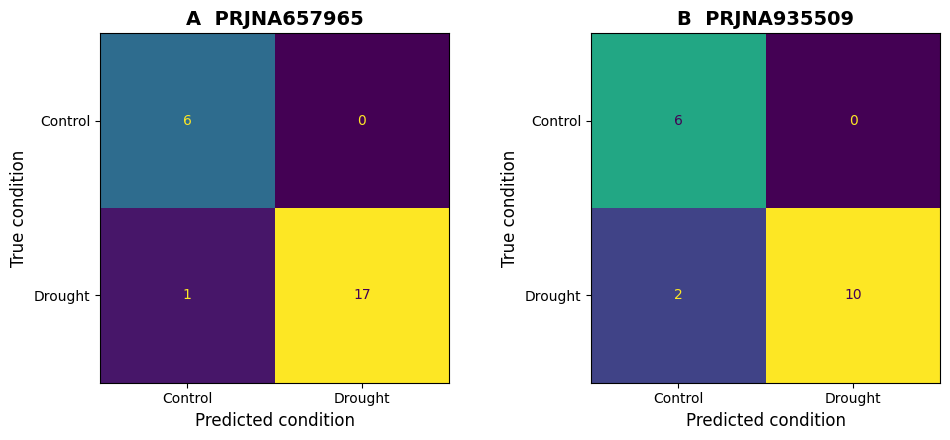

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrices from the external-validation results
# Format:
# [[TN, FP],
#  [FN, TP]]

cm_657965 = np.array([
    [6, 0],
    [1, 17]
])

cm_935509 = np.array([
    [6, 0],
    [2, 10]
])

class_labels = ["Control", "Drought"]

# Create combined publication-ready figure
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Panel A
disp1 = ConfusionMatrixDisplay(
    confusion_matrix=cm_657965,
    display_labels=class_labels
)
disp1.plot(
    ax=axes[0],
    values_format="d",
    colorbar=False
)

axes[0].set_title(
    "A  PRJNA657965",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_xlabel("Predicted condition", fontsize=12)
axes[0].set_ylabel("True condition", fontsize=12)

# Panel B
disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_935509,
    display_labels=class_labels
)
disp2.plot(
    ax=axes[1],
    values_format="d",
    colorbar=False
)

axes[1].set_title(
    "B  PRJNA935509",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Predicted condition", fontsize=12)
axes[1].set_ylabel("True condition", fontsize=12)

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "External_Validation_Confusion_Matrices.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

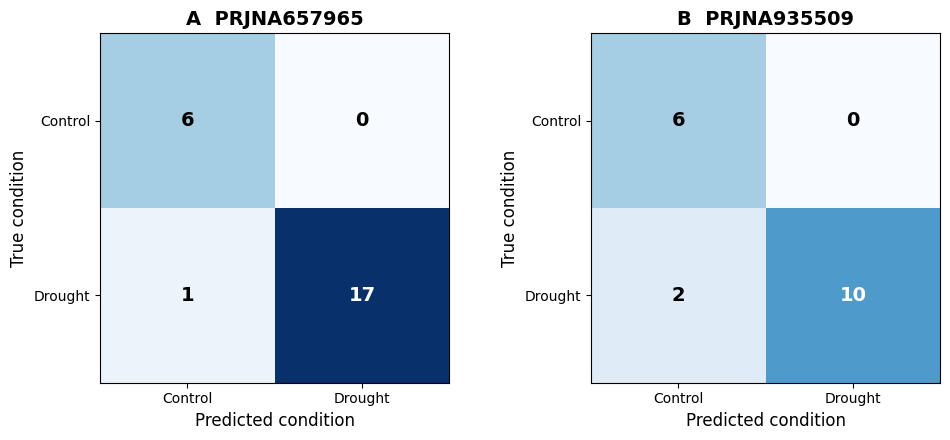

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

cm1 = np.array([[6, 0],
                [1, 17]])

cm2 = np.array([[6, 0],
                [2, 10]])

labels = ["Control", "Drought"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Same scale for BOTH panels
vmax = max(cm1.max(), cm2.max())

for ax, cm, title in zip(
    axes,
    [cm1, cm2],
    ["A  PRJNA657965", "B  PRJNA935509"]
):
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=vmax)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(labels)
    ax.set_yticklabels(labels)

    ax.set_xlabel("Predicted condition", fontsize=12)
    ax.set_ylabel("True condition", fontsize=12)
    ax.set_title(title, fontsize=14, fontweight="bold")

    # Add counts with readable text
    for i in range(2):
        for j in range(2):
            text_color = "white" if cm[i, j] > vmax/2 else "black"
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=14,
                fontweight="bold",
                color=text_color
            )

plt.tight_layout()

plt.savefig(
    "External_Validation_Confusion_Matrices_PUBLICATION.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

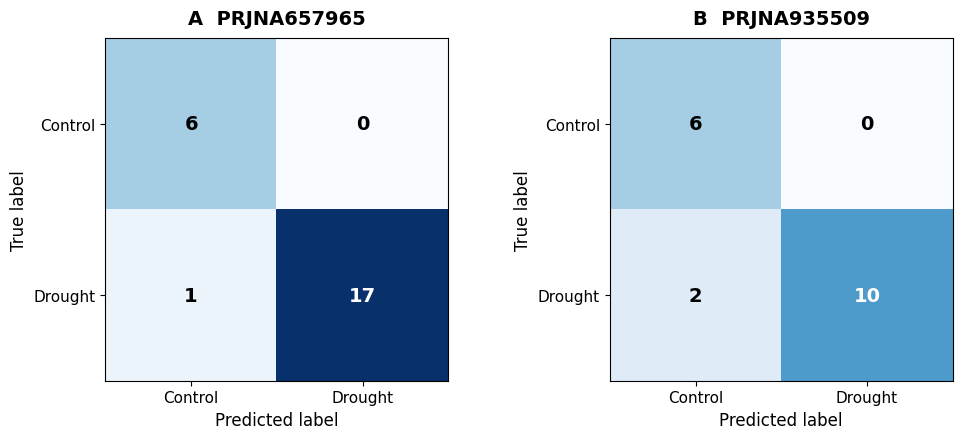

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# External-validation confusion matrices
cm1 = np.array([
    [6, 0],
    [1, 17]
])

cm2 = np.array([
    [6, 0],
    [2, 10]
])

labels = ["Control", "Drought"]

# Same color scale for both panels
vmax = max(cm1.max(), cm2.max())

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

for ax, cm, title in zip(
    axes,
    [cm1, cm2],
    ["A  PRJNA657965", "B  PRJNA935509"]
):
    ax.imshow(
        cm,
        cmap="Blues",
        vmin=0,
        vmax=vmax
    )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(labels, fontsize=11)
    ax.set_yticklabels(labels, fontsize=11)

    # Match terminology used in the earlier manuscript figure
    ax.set_xlabel("Predicted label", fontsize=12)
    ax.set_ylabel("True label", fontsize=12)

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=10
    )

    # Cell counts
    for i in range(2):
        for j in range(2):
            color = "white" if cm[i, j] > vmax / 2 else "black"

            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=14,
                fontweight="bold",
                color=color
            )

# Keep panels well spaced
plt.tight_layout(w_pad=3)

# Save publication-quality figure
plt.savefig(
    "External_Validation_Confusion_Matrices_FINAL.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ==========================================================
# Bootstrap 95% CIs for external validation metrics
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score
)

RNG = np.random.default_rng(42)

def bootstrap_metric_ci(df, n_boot=5000):
    X_ext = df[FROZEN_GENES].copy()

    y_true = df["Condition"].map({
        "Control": 0,
        "Drought": 1
    }).values

    y_pred = frozen_model.predict(X_ext)
    y_prob = frozen_model.predict_proba(X_ext)[:, 1]

    metrics = {
        "Balanced_Accuracy": lambda yt, yp, pr: balanced_accuracy_score(yt, yp),
        "F1": lambda yt, yp, pr: f1_score(yt, yp),
        "MCC": lambda yt, yp, pr: matthews_corrcoef(yt, yp),
        "ROC_AUC": lambda yt, yp, pr: roc_auc_score(yt, pr)
    }

    results = []

    for metric_name, metric_func in metrics.items():

        boot_vals = []

        for _ in range(n_boot):
            idx = RNG.integers(0, len(y_true), len(y_true))

            yt = y_true[idx]
            yp = y_pred[idx]
            pr = y_prob[idx]

            # Need both classes present for balanced accuracy / ROC-AUC
            if len(np.unique(yt)) < 2:
                continue

            try:
                val = metric_func(yt, yp, pr)
                boot_vals.append(val)
            except:
                continue

        boot_vals = np.array(boot_vals)

        point_estimate = metric_func(y_true, y_pred, y_prob)

        lower = np.percentile(boot_vals, 2.5)
        upper = np.percentile(boot_vals, 97.5)

        results.append({
            "Metric": metric_name,
            "Estimate": point_estimate,
            "CI_Lower_95": lower,
            "CI_Upper_95": upper,
            "Bootstrap_Replicates_Used": len(boot_vals)
        })

    return pd.DataFrame(results)


jiang_ci = bootstrap_metric_ci(jiang_ext, n_boot=5000)
sun_ci = bootstrap_metric_ci(sun_ext, n_boot=5000)

jiang_ci.insert(0, "Dataset", "Jiang")
sun_ci.insert(0, "Dataset", "Sun")

external_ci = pd.concat(
    [jiang_ci, sun_ci],
    ignore_index=True
)

display(external_ci)

external_ci.to_csv(
    "FINAL_external_validation_95CI.csv",
    index=False
)

print("✓ Bootstrap 95% confidence intervals calculated.")

,Dataset,Metric,Estimate,CI_Lower_95,CI_Upper_95,Bootstrap_Replicates_Used
0,Jiang,Balanced_Accuracy,0.972222,0.911765,1.0,4995
1,Jiang,F1,0.971429,0.903226,1.0,4997
2,Jiang,MCC,0.899735,0.674200,1.0,4996
3,Jiang,ROC_AUC,1.000000,1.000000,1.0,4994
4,Sun,Balanced_Accuracy,0.916667,0.800000,1.0,4995
5,Sun,F1,0.909091,0.736842,1.0,4999
6,Sun,MCC,0.790569,0.500000,1.0,4997
7,Sun,ROC_AUC,1.000000,1.000000,1.0,4994


✓ Bootstrap 95% confidence intervals calculated.
